# BCV dimension-estimation report

This notebook reports and visualizes the BCV (bi-cross-validation) results
produced by:

- **`test_bcv_capability.py`** &rarr; `results/bcv_capability.csv` &mdash; timing
  and recovery as we scale **n**, **true dimension** (incl. the `n ~= items`
  regime), and **sigma** (noise level), with the ADMM solver using all cores but
  one.
- **`generate_bcv_examples.py`** &rarr; `results/bcv_examples_*.{csv,pkl}` &mdash;
  a factorial set of examples with full per-dimension BCV curves.

The improved BCV uses **parallel analysis** to center the rank-search grid and
the **1-SE rule** to pick the dimension off the (noisy) CV curve.

> Run `python test_bcv_capability.py` and `python generate_bcv_examples.py`
> first (add `--quick` for a fast smoke run).

In [1]:
import pickle
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# This notebook lives in testing/. Add the repo root to sys.path so `import icqf`
# and `bcv_simdata` resolve, and anchor RESULTS to testing/results regardless of
# where the kernel was launched.
_HERE = Path.cwd()
_TESTING = _HERE if (_HERE / "bcv_simdata.py").exists() else _HERE / "testing"
sys.path.insert(0, str(_TESTING))                 # bcv_simdata
sys.path.insert(0, str(_TESTING.parent))          # repo root -> icqf
RESULTS = _TESTING / "results"
pd.set_option("display.width", 140)

cap_df    = pd.read_csv(RESULTS / "bcv_capability.csv")   if (RESULTS / "bcv_capability.csv").exists() else None
index_df  = pd.read_csv(RESULTS / "bcv_examples_index.csv")
curves_df = pd.read_csv(RESULTS / "bcv_examples_curves.csv")
with open(RESULTS / "bcv_examples.pkl", "rb") as f:
    blob = pickle.load(f)
bundles = {b["example_id"]: b for b in blob["bundles"]}
design = blob.get("design", {})

print(f"capability rows : {0 if cap_df is None else len(cap_df)}")
print(f"examples        : {len(index_df)}")
print(f"curve points    : {len(curves_df)}")
print(f"BCV config      : J={design.get('J')} folds x repeat={design.get('repeat')} "
      f"=> {design.get('J', 0) * design.get('repeat', 0)} CV replicates, "
      f"max_iter={design.get('max_iter')}")
# Selection settings recorded per example (from the first bundle's selection_info).
_sel0 = next(iter(bundles.values()))["selection_info"]
print(f"selection rule  : {_sel0.get('rule')} (se_mult={_sel0.get('se_mult')}, "
      f"se_col={_sel0.get('se_col')})")

capability rows : 20
examples        : 64
curve points    : 650
BCV config      : J=10 folds x repeat=2 => 20 CV replicates, max_iter=200
selection rule  : 1se (se_mult=1.0, se_col=test_mse_se)


## 0. The synthetic example

Every example is a **non-negative, low-rank** matrix with a *known* true rank,
built by `bcv_simdata.make_lowrank_df` (the same recipe as `demo_ICQF.ipynb`):

$$M \;=\; \operatorname{clip}\!\Big(\underbrace{W_{\text{true}}\,Q_{\text{true}}^{\top}}_{\text{rank-}d\text{ signal},\,\in[0,1]} \;+\; \mathcal{N}(0,\sigma^2),\; 0,\, 1\Big)$$

- $W_{\text{true}}\in\mathbb{R}^{n\times d}_{\ge 0}$ are dense subject scores,
- $Q_{\text{true}}\in\mathbb{R}^{p\times d}_{\ge 0}$ are **sparse** item loadings
  (controlled by `q_density`), so each factor loads on a subset of items,
- $\sigma$ is the observation-noise level and $d$ the true embedding dimension.

BCV's job is to recover $d$ from $M$ alone. Below is a small, illustrative
instance so the structure is visible (the actual study uses $n\in[200,500]$).

demo meta: {'n': 60, 'p': 40, 'true_dim': 4, 'sigma': 0.05, 'q_density': 0.5, 'snr': 12.308639670730635}


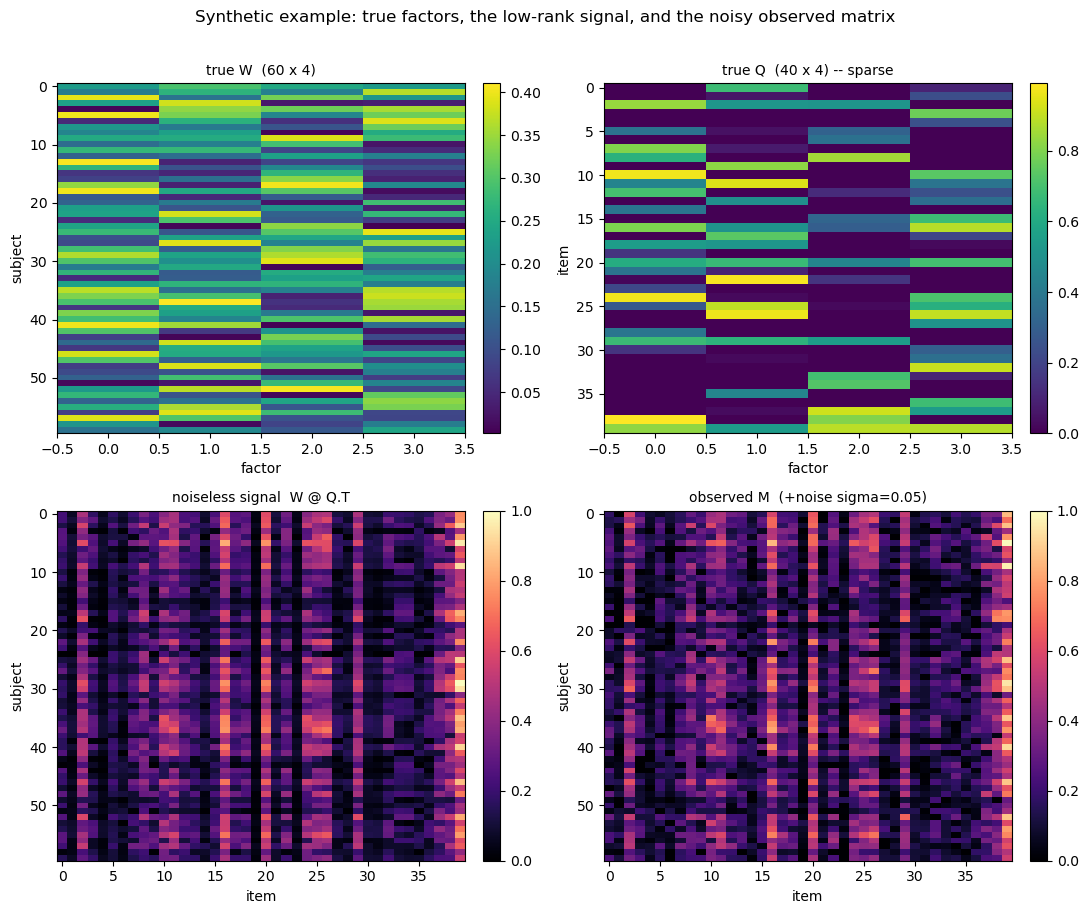

In [2]:
from bcv_simdata import make_lowrank_df

# A small instance purely for visualization (same generator as the study).
demo_n, demo_p, demo_d, demo_sigma = 60, 40, 4, 0.05
M_demo, demo_meta, W_true, Q_true = make_lowrank_df(
    demo_n, demo_p, demo_d, sigma=demo_sigma, q_density=0.5, seed=0,
    return_factors=True,
)
signal = W_true.to_numpy() @ Q_true.to_numpy().T
print("demo meta:", {k: demo_meta[k] for k in ['n', 'p', 'true_dim', 'sigma', 'q_density', 'snr']})

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
panels = [
    (axes[0, 0], W_true.to_numpy(), "viridis", None, f"true W  ({demo_n} x {demo_d})", "factor", "subject"),
    (axes[0, 1], Q_true.to_numpy(), "viridis", None, f"true Q  ({demo_p} x {demo_d}) -- sparse", "factor", "item"),
    (axes[1, 0], signal, "magma", (0, 1), "noiseless signal  W @ Q.T", "item", "subject"),
    (axes[1, 1], M_demo.to_numpy(), "magma", (0, 1), f"observed M  (+noise sigma={demo_sigma})", "item", "subject"),
]
for ax, mat, cmap, vlim, title, xl, yl in panels:
    vmin, vmax = (vlim if vlim else (None, None))
    im = ax.imshow(mat, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("Synthetic example: true factors, the low-rank signal, and the noisy observed matrix", y=1.01)
plt.tight_layout(); plt.show()

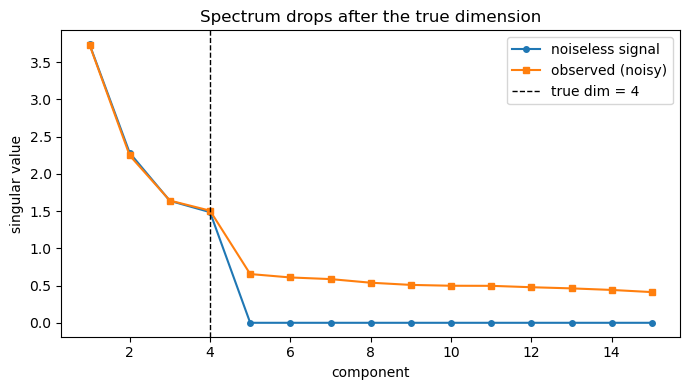

In [3]:
# Singular-value spectrum of the signal vs the noisy matrix: the rank-d "elbow".
sv_signal = np.linalg.svd(signal - signal.mean(0), compute_uv=False)
sv_obs    = np.linalg.svd(M_demo.to_numpy() - M_demo.to_numpy().mean(0), compute_uv=False)
fig, ax = plt.subplots(figsize=(7, 4))
K = 15
ax.plot(np.arange(1, K + 1), sv_signal[:K], "-o", ms=4, label="noiseless signal")
ax.plot(np.arange(1, K + 1), sv_obs[:K], "-s", ms=4, label="observed (noisy)")
ax.axvline(demo_d, color="k", ls="--", lw=1, label=f"true dim = {demo_d}")
ax.set_xlabel("component"); ax.set_ylabel("singular value")
ax.set_title("Spectrum drops after the true dimension"); ax.legend()
plt.tight_layout(); plt.show()

## 1. Headline recovery accuracy: naive argmin vs 1-SE rule

Two refinements drive the selection quality here:

- **More folds.** BCV now uses **J=10** folds x **repeat=2** = 20 CV replicates
  (up from a handful). A noisy 3-fold curve can be monotone or have a jittery
  minimum; averaging 20 held-out splits gives a curve with a clean basin at the
  true rank.
- **Fold-paired SE + `se_mult`.** The same folds score every rank, so each fold's
  overall difficulty is a constant offset across ranks that inflates the naive
  SE. The **paired** SE centers each fold's curve first, giving a tighter, fairer
  band; `se_mult` scales it (1.0 = classic 1-SE).

In [4]:
acc = pd.DataFrame({
    "argmin": {
        "accuracy (exact)": index_df["correct_argmin"].mean(),
        "mean |error|":     index_df["err_argmin"].abs().mean(),
        "mean signed error":index_df["err_argmin"].mean(),
    },
    "1-SE": {
        "accuracy (exact)": index_df["correct_1se"].mean(),
        "mean |error|":     index_df["err_1se"].abs().mean(),
        "mean signed error":index_df["err_1se"].mean(),
    },
}).T
display(acc.style.format("{:.3f}"))

,accuracy (exact),mean |error|,mean signed error
argmin,0.703,0.500,0.250
1-SE,0.766,0.359,0.109


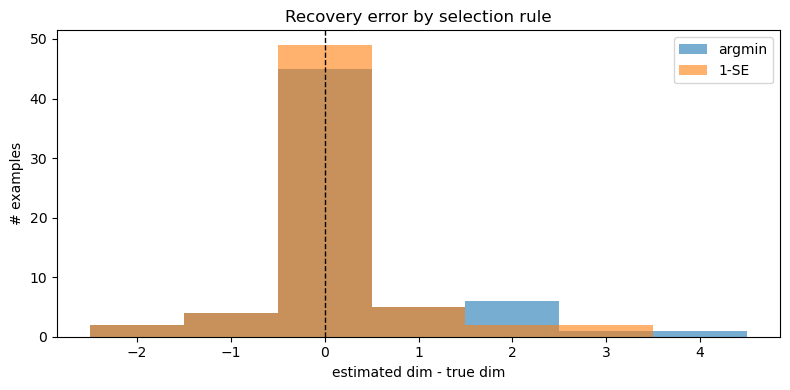

In [5]:
# Error distribution (estimate - true) for both rules
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(index_df[["err_argmin", "err_1se"]].min().min() - 0.5,
                 index_df[["err_argmin", "err_1se"]].max().max() + 1.5, 1)
ax.hist(index_df["err_argmin"], bins=bins, alpha=0.6, label="argmin")
ax.hist(index_df["err_1se"],    bins=bins, alpha=0.6, label="1-SE")
ax.axvline(0, color="k", lw=1, ls="--")
ax.set_xlabel("estimated dim - true dim"); ax.set_ylabel("# examples")
ax.set_title("Recovery error by selection rule"); ax.legend()
plt.tight_layout(); plt.show()

### Why fold-paired SE: raw vs paired band

For one example, the band the SE rule compares against, drawn with the **raw**
across-replicate SE vs the **fold-paired** SE. The paired band is tighter (the
fold-difficulty offset has been removed), so the rule is less prone to
over-simplifying down a flat curve.

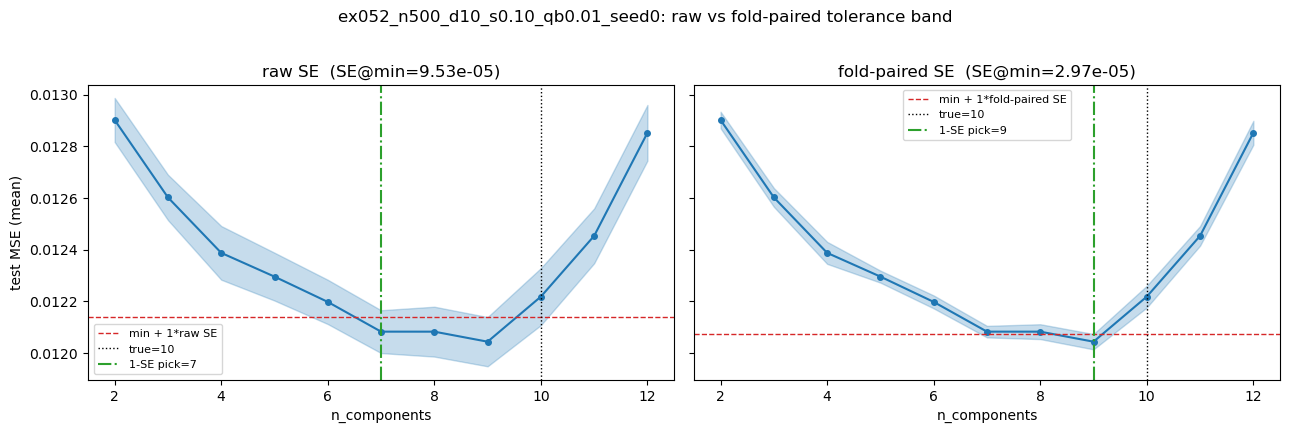

In [6]:
# Pick the example whose curve is flattest near its minimum (most SE-sensitive).
def _flatness(b):
    s = b["summary_df"].sort_values("n_components")
    mu = s["test_mse_mean"].to_numpy()
    return (mu.max() - mu.min()) / (mu.min() + 1e-12)
ex_id = min(bundles, key=lambda e: _flatness(bundles[e]))
b = bundles[ex_id]; s = b["summary_df"].sort_values("n_components"); m = b["meta"]
k = s["n_components"].to_numpy(); mu = s["test_mse_mean"].to_numpy()
se_raw = s["test_mse_se_raw"].to_numpy(); se_pair = s["test_mse_se_paired"].to_numpy()
rmin = int(np.argmin(mu))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, se, name in [(axes[0], se_raw, "raw SE"), (axes[1], se_pair, "fold-paired SE")]:
    ax.plot(k, mu, "-o", ms=4, color="C0")
    ax.fill_between(k, mu - se, mu + se, alpha=0.25, color="C0")
    thr = mu[rmin] + se[rmin]
    ax.axhline(thr, color="C3", ls="--", lw=1, label=f"min + 1*{name}")
    pick = int(k[np.where(mu <= thr)[0][0]])
    ax.axvline(m["true_dim"], color="k", ls=":", lw=1, label=f"true={m['true_dim']}")
    ax.axvline(pick, color="C2", ls="-.", lw=1.5, label=f"1-SE pick={pick}")
    ax.set_xlabel("n_components"); ax.set_title(f"{name}  (SE@min={se[rmin]:.2e})")
    ax.legend(fontsize=8)
axes[0].set_ylabel("test MSE (mean)")
fig.suptitle(f"{ex_id}: raw vs fold-paired tolerance band", y=1.02)
plt.tight_layout(); plt.show()

## 2. BCV curves per example

Test MSE vs candidate rank. The dashed vertical line is the **true** dimension;
markers show the **argmin** and **1-SE** picks. The shaded band is +/-1
*fold-paired* SE (the band the 1-SE rule actually uses).

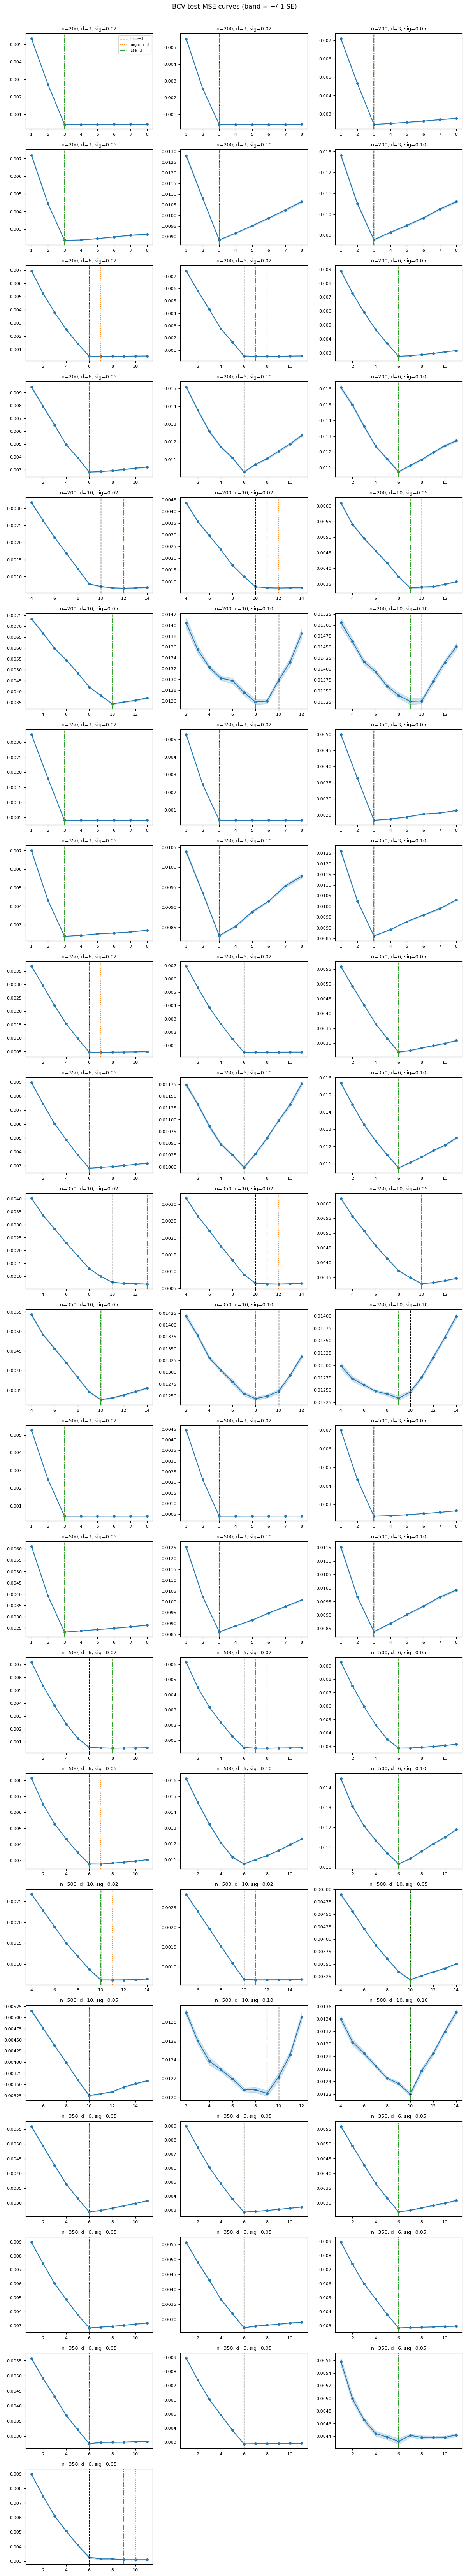

In [7]:
def plot_curve(ax, ex_id):
    b = bundles[ex_id]; s = b["summary_df"]; m = b["meta"]
    k = s["n_components"].to_numpy()
    mu = s["test_mse_mean"].to_numpy(); se = s["test_mse_se"].to_numpy()
    ax.plot(k, mu, "-o", ms=4, color="C0")
    ax.fill_between(k, mu - se, mu + se, alpha=0.2, color="C0")
    ax.axvline(m["true_dim"], color="k", ls="--", lw=1, label=f"true={m['true_dim']}")
    ax.axvline(b["best_k_argmin"], color="C1", ls=":", lw=1.5, label=f"argmin={b['best_k_argmin']}")
    ax.axvline(b["best_k_1se"],    color="C2", ls="-.", lw=1.5, label=f"1se={b['best_k_1se']}")
    ax.set_title(f"n={m['n']}, d={m['true_dim']}, sig={m['sigma']:.2f}", fontsize=9)
    ax.tick_params(labelsize=8)

ex_ids = index_df["example_id"].tolist()
ncols = 3
nrows = int(np.ceil(len(ex_ids) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)
for i, ex_id in enumerate(ex_ids):
    plot_curve(axes[i // ncols][i % ncols], ex_id)
for j in range(len(ex_ids), nrows * ncols):
    axes[j // ncols][j % ncols].axis("off")
axes[0][0].legend(fontsize=7)
fig.suptitle("BCV test-MSE curves (band = +/-1 SE)", y=1.002)
plt.tight_layout(); plt.show()

## 3. Recovery vs true dimension, n, and noise

These panels use the **core factorial** examples (default `Q_beta`); the Q-sparsity
sweep is analyzed separately in section 3b.

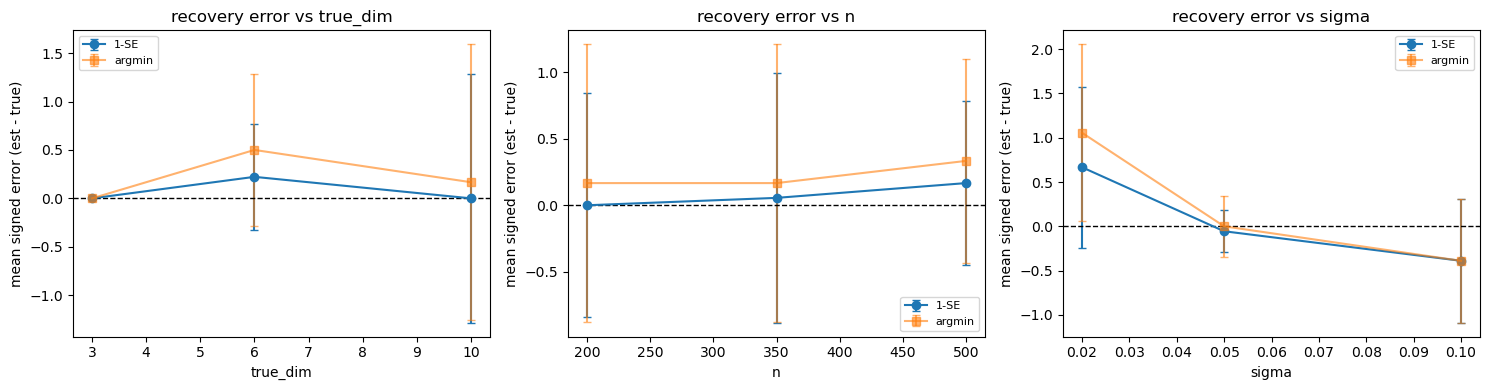

In [8]:
# Restrict to the core factorial group so the Q_beta sweep doesn't contaminate
# the n / true_dim / sigma axes.
fac = index_df[index_df["group"] == "factorial"] if "group" in index_df else index_df

# Signed error of the 1-SE estimate as a function of each axis.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, axis in zip(axes, ["true_dim", "n", "sigma"]):
    g = fac.groupby(axis)["err_1se"]
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                fmt="-o", capsize=3, label="1-SE")
    g2 = fac.groupby(axis)["err_argmin"]
    ax.errorbar(g2.mean().index, g2.mean().values, yerr=g2.std().values,
                fmt="-s", capsize=3, alpha=0.6, label="argmin")
    ax.axhline(0, color="k", lw=1, ls="--")
    ax.set_xlabel(axis); ax.set_ylabel("mean signed error (est - true)")
    ax.set_title(f"recovery error vs {axis}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

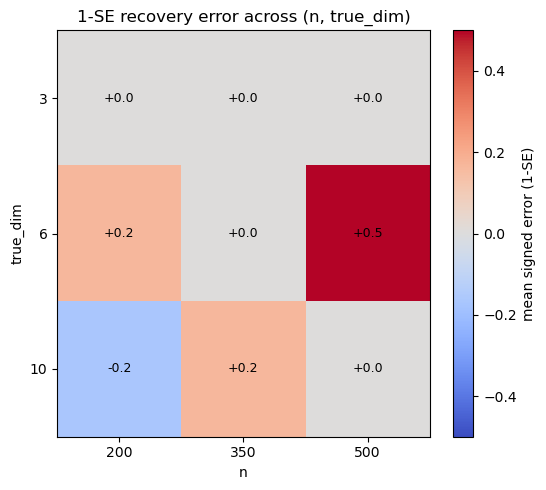

In [9]:
# Heatmap of 1-SE signed error over (n x true_dim), averaged over seeds & sigma.
piv = fac.pivot_table(index="true_dim", columns="n", values="err_1se", aggfunc="mean")
fig, ax = plt.subplots(figsize=(1.2 * piv.shape[1] + 2, 1.0 * piv.shape[0] + 2))
im = ax.imshow(piv.values, cmap="coolwarm", vmin=-abs(piv.values).max() - 1e-9,
               vmax=abs(piv.values).max() + 1e-9, aspect="auto")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
ax.set_xlabel("n"); ax.set_ylabel("true_dim")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="mean signed error (1-SE)")
ax.set_title("1-SE recovery error across (n, true_dim)")
plt.tight_layout(); plt.show()

## 3b. Effect of Q sparsity ($Q_\beta$)

Here the data is held fixed (one $n$, true_dim, $\sigma$) and ICQF's $Q_\beta$
L1 penalty on the item loadings is swept. Larger $Q_\beta$ pushes $Q$ toward
**sparser** loadings; we check whether the recovered BCV dimension is stable
across the penalty, and how the held-out curve shifts.

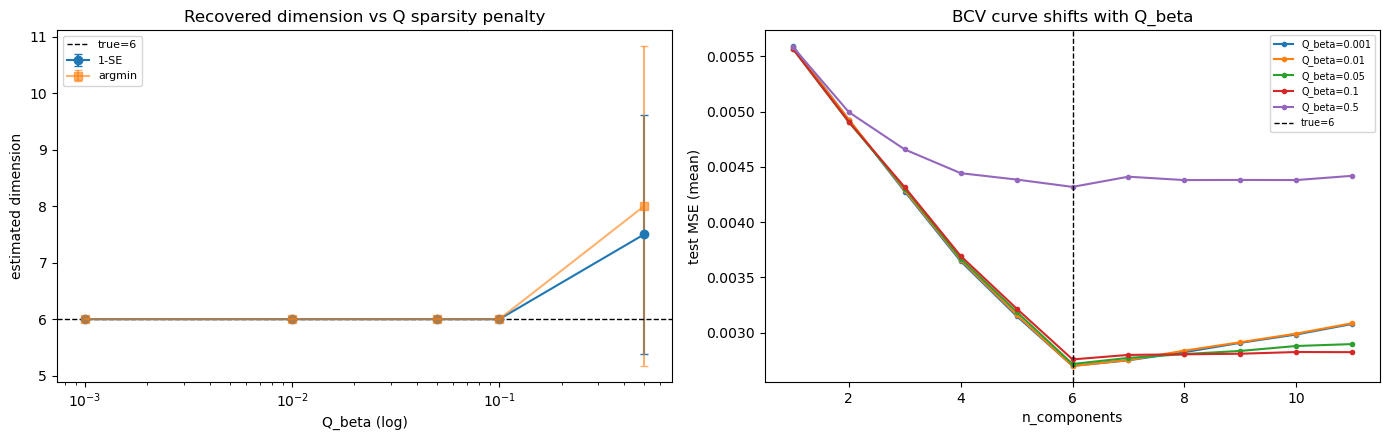

,example_id,q_beta,seed,pa_dim,best_k_argmin,best_k_1se,bcv_time_sec
54,ex054_n350_d6_s0.05_qb0.001_seed0,0.001,0,6,6,6,31.686287
55,ex055_n350_d6_s0.05_qb0.001_seed1,0.001,1,6,6,6,29.345979
56,ex056_n350_d6_s0.05_qb0.01_seed0,0.010,0,6,6,6,28.838802
57,ex057_n350_d6_s0.05_qb0.01_seed1,0.010,1,6,6,6,56.977352
58,ex058_n350_d6_s0.05_qb0.05_seed0,0.050,0,6,6,6,37.533747
59,ex059_n350_d6_s0.05_qb0.05_seed1,0.050,1,6,6,6,88.698175
60,ex060_n350_d6_s0.05_qb0.1_seed0,0.100,0,6,6,6,37.796337
61,ex061_n350_d6_s0.05_qb0.1_seed1,0.100,1,6,6,6,48.815410
62,ex062_n350_d6_s0.05_qb0.5_seed0,0.500,0,6,6,6,56.578116
63,ex063_n350_d6_s0.05_qb0.5_seed1,0.500,1,6,10,9,39.705177


In [10]:
qb = index_df[index_df["group"] == "qbeta_sweep"].copy() if "group" in index_df else index_df.iloc[0:0]
if len(qb):
    true_d = int(qb["true_dim"].iloc[0])
    # left: estimated dim vs Q_beta (mean over seeds); right: BCV curves per Q_beta.
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 4.5))

    g1 = qb.groupby("q_beta")["best_k_1se"].agg(["mean", "std"])
    gA = qb.groupby("q_beta")["best_k_argmin"].agg(["mean", "std"])
    axL.errorbar(g1.index, g1["mean"], yerr=g1["std"].fillna(0), fmt="-o", capsize=3, label="1-SE")
    axL.errorbar(gA.index, gA["mean"], yerr=gA["std"].fillna(0), fmt="-s", capsize=3, alpha=0.6, label="argmin")
    axL.axhline(true_d, color="k", ls="--", lw=1, label=f"true={true_d}")
    axL.set_xscale("log"); axL.set_xlabel("Q_beta (log)"); axL.set_ylabel("estimated dimension")
    axL.set_title("Recovered dimension vs Q sparsity penalty"); axL.legend(fontsize=8)

    # one representative seed for the curves
    seed0 = qb["seed"].min()
    qb_curves = curves_df[(curves_df["group"] == "qbeta_sweep") & (curves_df["seed"] == seed0)]
    for q_beta, sub in qb_curves.groupby("q_beta"):
        sub = sub.sort_values("n_components")
        axR.plot(sub["n_components"], sub["test_mse_mean"], "-o", ms=3, label=f"Q_beta={q_beta:g}")
    axR.axvline(true_d, color="k", ls="--", lw=1, label=f"true={true_d}")
    axR.set_xlabel("n_components"); axR.set_ylabel("test MSE (mean)")
    axR.set_title("BCV curve shifts with Q_beta"); axR.legend(fontsize=7)
    plt.tight_layout(); plt.show()

    display(qb[["example_id", "q_beta", "seed", "pa_dim", "best_k_argmin",
                "best_k_1se", "bcv_time_sec"]].sort_values(["q_beta", "seed"]))
else:
    print("No Q_beta sweep found (group == 'qbeta_sweep'). "
          "Re-run generate_bcv_examples.py with the current version.")

## 4. Parallel-analysis spectra

For a few examples, the observed singular-value spectrum vs the permutation-null
threshold. The PA dimension is the number of observed values above the null and
is used to **center** the BCV search window.

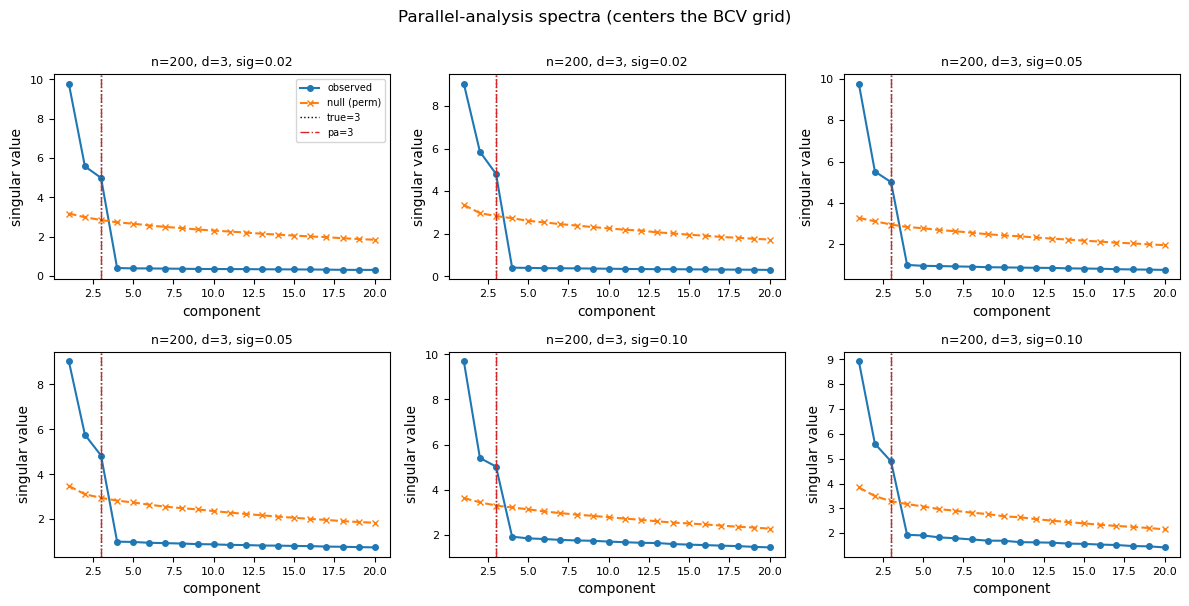

In [11]:
show = index_df["example_id"].tolist()[:6]
ncols = 3; nrows = int(np.ceil(len(show) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)
for i, ex_id in enumerate(show):
    ax = axes[i // ncols][i % ncols]
    pa = bundles[ex_id]["pa_info"]; m = bundles[ex_id]["meta"]
    sv = np.asarray(pa.get("observed_sv", []))
    th = np.asarray(pa.get("null_threshold", []))
    K = min(20, len(sv))
    x = np.arange(1, K + 1)
    ax.plot(x, sv[:K], "-o", ms=4, label="observed")
    ax.plot(x, th[:K], "--x", ms=4, label="null (perm)")
    ax.axvline(m["true_dim"], color="k", ls=":", lw=1, label=f"true={m['true_dim']}")
    ax.axvline(pa.get("pa_dim", np.nan), color="C3", ls="-.", lw=1, label=f"pa={pa.get('pa_dim')}")
    ax.set_title(f"n={m['n']}, d={m['true_dim']}, sig={m['sigma']:.2f}", fontsize=9)
    ax.set_xlabel("component"); ax.set_ylabel("singular value"); ax.tick_params(labelsize=8)
axes[0][0].legend(fontsize=7)
for j in range(len(show), nrows * ncols):
    axes[j // ncols][j % ncols].axis("off")
fig.suptitle("Parallel-analysis spectra (centers the BCV grid)", y=1.002)
plt.tight_layout(); plt.show()

## 5. Timing of BCV (ADMM on all cores but one)

ADMM BLAS threads used: 191


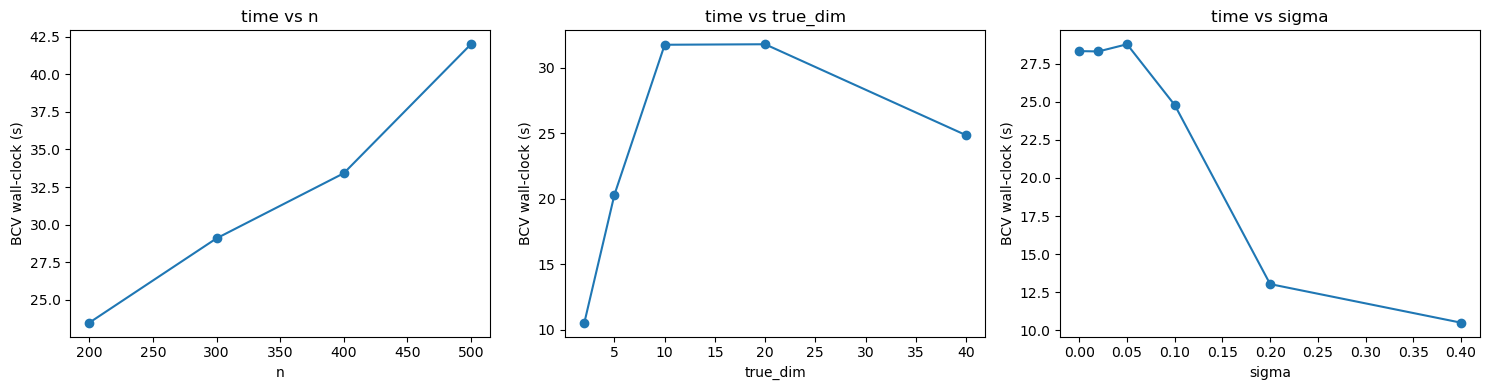

In [12]:
if cap_df is not None:
    n_threads = int(cap_df["n_threads"].iloc[0])
    print(f"ADMM BLAS threads used: {n_threads}")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    specs = [("vary_n", "n"), ("vary_true_dim", "true_dim"), ("vary_sigma", "sigma")]
    for ax, (sweep, axis) in zip(axes, specs):
        sub = cap_df[cap_df["sweep"] == sweep].sort_values(axis)
        if len(sub):
            ax.plot(sub[axis], sub["bcv_time_sec"], "-o")
            ax.set_xlabel(axis); ax.set_ylabel("BCV wall-clock (s)")
            ax.set_title(f"time vs {axis}")
    plt.tight_layout(); plt.show()
else:
    print("results/bcv_capability.csv not found - run test_bcv_capability.py")

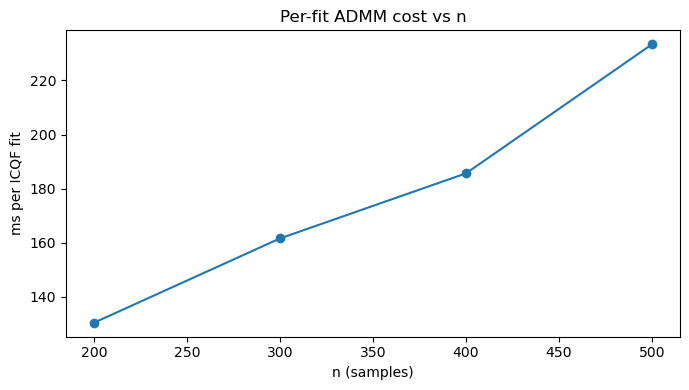

,sweep,n,p,true_dim,sigma,n_fits,bcv_time_sec,time_per_fit_sec,pa_dim,est_dim_argmin,est_dim_1se
0,baseline,300,80,8,0.05,180,27.754799,0.154193,8,8,8
1,vary_n,200,80,8,0.05,180,23.478103,0.130434,7,8,8
2,vary_n,300,80,8,0.05,180,29.087931,0.161600,8,8,8
3,vary_n,400,80,8,0.05,180,33.417976,0.185655,8,8,8
4,vary_n,500,80,8,0.05,180,42.002796,0.233349,8,8,8
5,vary_true_dim,300,80,2,0.05,120,10.530744,0.087756,2,2,2
6,vary_true_dim,300,80,5,0.05,180,20.323886,0.112910,5,5,5
7,vary_true_dim,300,80,10,0.05,180,31.774215,0.176523,10,10,10
8,vary_true_dim,300,80,20,0.05,180,31.812294,0.176735,12,16,16
9,vary_true_dim,300,80,40,0.05,180,24.866007,0.138144,8,11,11


In [13]:
if cap_df is not None:
    # Time-per-fit isolates the per-ICQF cost from the (grid x J x repeat) count.
    fig, ax = plt.subplots(figsize=(7, 4))
    sub = cap_df[cap_df["sweep"] == "vary_n"].sort_values("n")
    ax.plot(sub["n"], sub["time_per_fit_sec"] * 1e3, "-o")
    ax.set_xlabel("n (samples)"); ax.set_ylabel("ms per ICQF fit")
    ax.set_title("Per-fit ADMM cost vs n")
    plt.tight_layout(); plt.show()
    cols = ["sweep", "n", "p", "true_dim", "sigma", "n_fits",
            "bcv_time_sec", "time_per_fit_sec", "pa_dim", "est_dim_argmin", "est_dim_1se"]
    display(cap_df[cols])

## 6. Per-example index table

Everything in one place: configuration, PA guess, both picks, error, and timing.
Raw per-fold rows and per-dimension summaries live in `results/examples/`.

In [14]:
cols = ["example_id", "group", "n", "p", "true_dim", "sigma", "q_beta", "snr",
        "pa_dim", "best_k_argmin", "best_k_1se", "err_1se", "correct_1se", "bcv_time_sec"]
cols = [c for c in cols if c in index_df.columns]
display(index_df[cols].style.format({"sigma": "{:.2f}", "q_beta": "{:g}",
                                     "snr": "{:.1f}", "bcv_time_sec": "{:.2f}"}))

,example_id,group,n,p,true_dim,sigma,q_beta,snr,pa_dim,best_k_argmin,best_k_1se,err_1se,correct_1se,bcv_time_sec
0,ex000_n200_d3_s0.02_qb0.01_seed0,factorial,200,60,3,0.02,0.01,72.5,3,3,3,0,True,17.06
1,ex001_n200_d3_s0.02_qb0.01_seed1,factorial,200,60,3,0.02,0.01,69.8,3,3,3,0,True,11.65
2,ex002_n200_d3_s0.05_qb0.01_seed0,factorial,200,60,3,0.05,0.01,11.6,3,3,3,0,True,14.14
3,ex003_n200_d3_s0.05_qb0.01_seed1,factorial,200,60,3,0.05,0.01,11.2,3,3,3,0,True,16.26
4,ex004_n200_d3_s0.10_qb0.01_seed0,factorial,200,60,3,0.10,0.01,2.9,3,3,3,0,True,12.20
5,ex005_n200_d3_s0.10_qb0.01_seed1,factorial,200,60,3,0.10,0.01,2.8,3,3,3,0,True,12.26
6,ex006_n200_d6_s0.02_qb0.01_seed0,factorial,200,60,6,0.02,0.01,83.6,6,7,6,0,True,51.51
7,ex007_n200_d6_s0.02_qb0.01_seed1,factorial,200,60,6,0.02,0.01,83.4,6,8,7,1,False,24.17
8,ex008_n200_d6_s0.05_qb0.01_seed0,factorial,200,60,6,0.05,0.01,13.4,6,6,6,0,True,21.81
9,ex009_n200_d6_s0.05_qb0.01_seed1,factorial,200,60,6,0.05,0.01,13.3,6,6,6,0,True,23.08
